# 03 · Long-wait early warning: will this request wait more than 10 minutes?

**Question.** At the moment a rider requests a trip, can we tell whether the pickup will take more
than 10 minutes? If so, the platform can act before the rider gives up: add a pay premium to get
the trip accepted faster, show an honest arrival time, or widen the search radius.

This is a **real supervised model on real labels**: every trip in the 0.5% sample has its actual
wait (request → pickup).

**Rules for features: only what is known at request time.**
* the request: pickup zone and its cluster, drop-off borough, trip distance (the destination is
  entered up front), shared request, airport, app company;
* the calendar: hour, day of week, holiday;
* **live marketplace state, from the hour before the request**: trips and mean / 90th-percentile
  wait in the pickup zone, and the citywide mean wait. Using the *same* hour would leak (that
  hour's waits aren't known yet at request time).

**Split by time, not at random**: train on the earliest months, choose settings and calibrate on
the next month, test on the last two months. A random split would let the model learn from trips
in the same hour as the test trips.

**Caveat.** The data contains completed trips only. Riders who cancelled after a long wait are
missing, so the true long-wait rate is higher than measured here.

In [1]:
import lightgbm as lgb
import numpy as np
import pandas as pd
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

from ridepay import config, data, forecast, plots
from ridepay.records import show_verdict, write_metrics

SOURCE = data.source()
con = data.connect()
THRESHOLD_MIN = 10
clusters = data.load_table("zone_clusters")
con.register("clusters", clusters[["zone", "cluster", "cluster_name"]])

## Building the features in SQL

One query joins each sampled trip to the state of its pickup zone and of the city in the
**previous** hour.

In [2]:
df = con.sql(f"""
    WITH zone_prev AS (
        SELECT zone, hour + INTERVAL 1 HOUR AS hour,          -- state of the previous hour, keyed to the next
               trips AS prev_trips,
               wait_sum_sec / NULLIF(wait_n, 0) / 60 AS prev_wait_min,
               wait_p90_sec / 60.0 AS prev_wait_p90_min
        FROM zone_hour),
    city_prev AS (
        SELECT hour + INTERVAL 1 HOUR AS hour,
               SUM(wait_sum_sec) / SUM(wait_n) / 60 AS prev_city_wait_min,
               SUM(trips) AS prev_city_trips
        FROM zone_hour GROUP BY hour)
    SELECT t.month, t.request_datetime, t.PULocationID AS zone, c.cluster, c.cluster_name,
           pu.borough AS pu_borough,
           CASE WHEN t.DOLocationID = {config.OUTSIDE_NYC_ZONE} THEN 'Outside NYC' ELSE dz.borough END AS do_borough,
           t.trip_miles, t.platform, t.shared_request::INT AS shared_request, t.is_airport::INT AS is_airport,
           hour(t.request_datetime) AS hod, isodow(t.request_datetime) - 1 AS dow,
           zp.prev_trips, zp.prev_wait_min, zp.prev_wait_p90_min, cp.prev_city_wait_min, cp.prev_city_trips,
           (t.wait_sec > {THRESHOLD_MIN * 60})::INT AS long_wait
    FROM trips t
    JOIN zones pu ON pu.zone = t.PULocationID
    LEFT JOIN zones dz ON dz.zone = t.DOLocationID
    LEFT JOIN clusters c ON c.zone = t.PULocationID
    LEFT JOIN zone_prev zp ON zp.zone = t.PULocationID AND zp.hour = date_trunc('hour', t.request_datetime)
    LEFT JOIN city_prev cp ON cp.hour = date_trunc('hour', t.request_datetime)
    WHERE t.wait_valid
""").df()
df["prev_trips"] = df["prev_trips"].fillna(0)             # no row = no trips in that zone that hour
hol = forecast.holiday_dates(sorted(df["request_datetime"].dt.year.unique()))
df["holiday"] = df["request_datetime"].dt.normalize().isin(hol).astype(int)
df["do_borough"] = df["do_borough"].fillna("Unknown")
for c in ["cluster_name", "pu_borough", "do_borough", "platform"]:
    df[c] = df[c].astype("category")
print(f"{len(df):,} trips with a valid wait; long-wait rate {df['long_wait'].mean():.2%}")

months = sorted(df["month"].unique())
test_months, valid_month = months[-2:], months[-3]
train_months = months[:-3]
split = np.where(df["month"].isin(test_months), "test", np.where(df["month"] == valid_month, "valid", "train"))
df["split"] = split
print("train:", train_months[0], "to", train_months[-1], "| valid:", valid_month, "| test:", test_months)
df.groupby("split")["long_wait"].agg(["size", "mean"]).round(4)

1,787,098 trips with a valid wait; long-wait rate 5.44%


train: 2024-01 to 2025-03 | valid: 2025-04 | test: ['2025-05', '2025-06']


,size,mean
split,,
test,202867,0.0734
train,1486365,0.0522
valid,97866,0.0491


## Two models

* **Logistic regression** on one-hot categories and scaled numbers: the transparent baseline.
* **LightGBM**: captures interactions (a long trip from an outer zone at 3am is worse than the sum
  of its parts), with the pickup zone itself as a categorical feature.

In [3]:
NUM = ["trip_miles", "hod", "dow", "shared_request", "is_airport", "holiday", "prev_trips", "prev_wait_min",
       "prev_wait_p90_min", "prev_city_wait_min", "prev_city_trips"]
CAT = ["cluster_name", "pu_borough", "do_borough", "platform"]
train, valid, test = (df[df["split"] == s] for s in ["train", "valid", "test"])


def fill(d):
    out = d[NUM + CAT].copy()
    for c in NUM:
        out[c] = out[c].fillna(df.loc[df["split"] == "train", c].median())
    return out


logit = make_pipeline(
    ColumnTransformer([("num", StandardScaler(), NUM),
                       ("cat", OneHotEncoder(handle_unknown="ignore"), CAT + ["hod"])]),
    LogisticRegression(max_iter=2000, C=1.0))
logit.fit(fill(train), train["long_wait"])

LGB_FEATURES = NUM + CAT + ["zone"]
gbm = lgb.LGBMClassifier(n_estimators=3000, learning_rate=0.05, num_leaves=63, min_child_samples=200,
                         subsample=0.8, subsample_freq=1, colsample_bytree=0.9, verbose=-1, n_jobs=2)
gbm.fit(train[LGB_FEATURES], train["long_wait"], eval_X=valid[LGB_FEATURES], eval_y=valid["long_wait"],
        categorical_feature=CAT + ["zone"], callbacks=[lgb.early_stopping(100, verbose=False)])

raw = {"Logistic": (logit.predict_proba(fill(valid))[:, 1], logit.predict_proba(fill(test))[:, 1]),
       "LightGBM": (gbm.predict_proba(valid[LGB_FEATURES])[:, 1], gbm.predict_proba(test[LGB_FEATURES])[:, 1])}
print("LightGBM trees:", gbm.best_iteration_)

LightGBM trees: 230


## Calibration

The threshold decision below multiplies probabilities by dollar costs, so a predicted 20% must
mean 20%. Isotonic regression, fitted on the **validation** month only, maps raw scores to
calibrated probabilities; the test months are never touched.

In [4]:
scores, calibrators = {}, {}
for name, (pv, pt) in raw.items():
    iso = IsotonicRegression(out_of_bounds="clip", y_min=1e-4, y_max=1 - 1e-4).fit(pv, valid["long_wait"])
    calibrators[name] = iso
    scores[name] = iso.predict(pt)
y = test["long_wait"].to_numpy()
base_rate = float(train["long_wait"].mean())
metrics = pd.DataFrame({
    name: {"ROC AUC": roc_auc_score(y, p), "PR AUC": average_precision_score(y, p),
           "Brier": brier_score_loss(y, p), "log loss": log_loss(y, p)}
    for name, p in scores.items()}).T
metrics.loc["Base rate only"] = [0.5, y.mean(), brier_score_loss(y, np.full_like(y, base_rate, float)),
                                 log_loss(y, np.full_like(y, base_rate, float))]
metrics.round(4)

,ROC AUC,PR AUC,Brier,log loss
Logistic,0.7170,0.1869,0.0643,0.2414
LightGBM,0.7349,0.1960,0.0636,0.2368
Base rate only,0.5000,0.0734,0.0685,0.2665


largest decile gap between predicted and observed (LightGBM): 1.338%


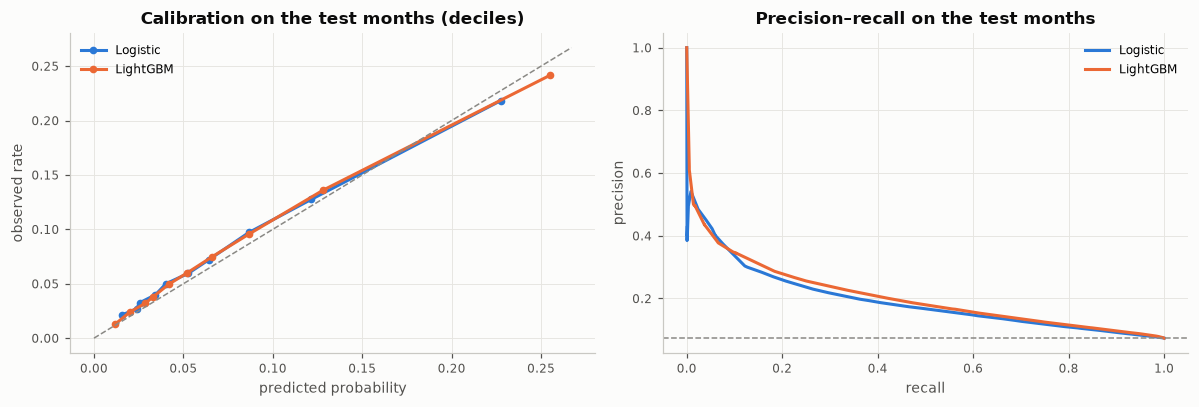

In [5]:
fig, axes = plots.subplots(1, 2, figsize=(11, 3.8))
for i, (name, p) in enumerate(scores.items()):
    bins = pd.qcut(p, 10, duplicates="drop")
    cal = pd.DataFrame({"p": p, "y": y}).groupby(bins, observed=True).mean()
    axes[0].plot(cal["p"], cal["y"], marker="o", ms=4, color=plots.SERIES[i], label=name)
lim = max(axes[0].get_xlim()[1], axes[0].get_ylim()[1])
axes[0].plot([0, lim], [0, lim], color=plots.GREY, lw=1, ls="--")
axes[0].set(title="Calibration on the test months (deciles)", xlabel="predicted probability", ylabel="observed rate")
axes[0].legend()
from sklearn.metrics import precision_recall_curve  # noqa: E402

for i, (name, p) in enumerate(scores.items()):
    prec, rec, _ = precision_recall_curve(y, p)
    axes[1].plot(rec, prec, color=plots.SERIES[i], label=name)
axes[1].axhline(y.mean(), color=plots.GREY, lw=1, ls="--")
axes[1].set(title="Precision–recall on the test months", xlabel="recall", ylabel="precision")
axes[1].legend()
fig.tight_layout()
data.savefig(fig, "03_calibration_pr")
cal_dev = (pd.DataFrame({"p": scores["LightGBM"], "y": y}).groupby(pd.qcut(scores["LightGBM"], 10, duplicates="drop"), observed=True)
           .mean().pipe(lambda d: (d["p"] - d["y"]).abs().max()))
print(f"largest decile gap between predicted and observed (LightGBM): {cal_dev:.3%}")

## Choosing the threshold by cost, not by accuracy

Flagging a request triggers an intervention (e.g. a pickup premium). Assumptions, stated so they
can be challenged:
* an intervention costs **\$1** per flagged request, needed or not;
* a long wait that isn't prevented costs **\$8** of expected future margin (some riders cancel or
  ride less afterwards);
* the intervention prevents the long wait when it would have happened (optimistic; phase 6
  models the real effect of pay on acceptance).

The decision threshold is fixed **before** looking at the test months: 1/9, from the costs and
calibration alone. The test-month cost curve then checks whether that was close to the best
threshold in hindsight.

Flag when p × \$8 > \$1, i.e. p > 1/9 ≈ 0.11 if probabilities are calibrated. The curve below
checks that by computing the cost on the test months at every threshold.

threshold 0.111: flags 15.4% of requests, precision 20.1%, recall 42.1%; best in hindsight 0.12


,cost per request ($)
Do nothing,0.5875
Flag every request,1.0000
"Model, threshold 0.111 (fixed in advance)",0.4942
"Model, best threshold in hindsight (0.12)",0.4942


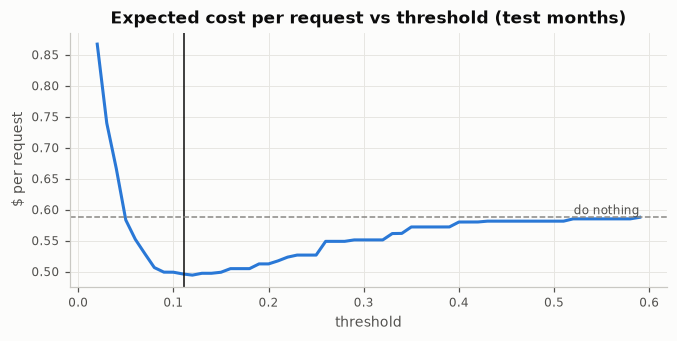

In [6]:
C_FLAG, C_MISS = 1.0, 8.0
p = scores["LightGBM"]
grid = np.round(np.arange(0.02, 0.6, 0.01), 2)
cost = np.array([(C_FLAG * (p >= t).sum() + C_MISS * ((p < t) & (y == 1)).sum()) / len(y) for t in grid])
best_t = float(grid[cost.argmin()])                 # best in hindsight, for checking only
theory_t = C_FLAG / (C_FLAG + C_MISS)                # the decision rule, fixed in advance
flag = p >= theory_t
cost_rule = (C_FLAG * flag.sum() + C_MISS * (~flag & (y == 1)).sum()) / len(y)
policy = pd.DataFrame({
    "cost per request ($)": {"Do nothing": C_MISS * y.mean(), "Flag every request": C_FLAG,
                             f"Model, threshold {theory_t:.3f} (fixed in advance)": cost_rule,
                             f"Model, best threshold in hindsight ({best_t:.2f})": cost.min()},
})
prec_at, rec_at, flagged_at = float(y[flag].mean()), float(flag[y == 1].mean()), float(flag.mean())
print(f"threshold {theory_t:.3f}: flags {flagged_at:.1%} of requests, precision {prec_at:.1%}, recall {rec_at:.1%}; "
      f"best in hindsight {best_t:.2f}")
sens = pd.DataFrame([{"cost of a long wait": cm, "best threshold": float(grid[np.argmin(
    [(C_FLAG * (p >= t).sum() + cm * ((p < t) & (y == 1)).sum()) for t in grid])])} for cm in [4, 8, 16]])
fig, ax = plots.subplots(figsize=(7, 3))
ax.plot(grid, cost, color=plots.SERIES[0])
ax.axvline(theory_t, color=plots.INK, lw=1)
ax.axhline(C_MISS * y.mean(), color=plots.GREY, ls="--", lw=1)
ax.text(grid[-1], C_MISS * y.mean(), "do nothing", ha="right", va="bottom", fontsize=8, color=plots.INK_2)
ax.set(title="Expected cost per request vs threshold (test months)", xlabel="threshold", ylabel="$ per request")
data.savefig(fig, "03_threshold_cost")
policy.round(4)

In [7]:
sens

,cost of a long wait,best threshold
0,4,0.28
1,8,0.12
2,16,0.06


In [8]:
imp = pd.Series(gbm.booster_.feature_importance("gain"), index=LGB_FEATURES)
imp = (imp / imp.sum()).sort_values(ascending=False).round(3)
by_cluster = test.assign(p=p).groupby("cluster_name", observed=True).agg(
    trips=("long_wait", "size"), long_wait_rate=("long_wait", "mean"), mean_pred=("p", "mean"),
    flagged=("p", lambda s: (s >= theory_t).mean()))
imp.head(10)

prev_wait_p90_min     0.313
zone                  0.221
prev_wait_min         0.191
shared_request        0.072
hod                   0.053
prev_city_trips       0.033
platform              0.027
trip_miles            0.025
prev_city_wait_min    0.021
prev_trips            0.017
dtype: float64

In [9]:
by_cluster.round(4)

,trips,long_wait_rate,mean_pred,flagged
cluster_name,,,,
Airports,8062,0.1934,0.1872,0.6026
Commuter residential,94680,0.0711,0.0648,0.1283
Core,98879,0.0644,0.0624,0.1376
Long waits,1244,0.1921,0.1754,0.5201
Sparse,2,0.5000,0.0871,0.0000


In [10]:
record = {
    "threshold_min": THRESHOLD_MIN, "n_trips": len(df), "long_wait_rate": float(df["long_wait"].mean()),
    "split": {"train": [train_months[0], train_months[-1]], "valid": valid_month, "test": test_months},
    "metrics": metrics.round(5).to_dict(orient="index"), "max_decile_calibration_gap": float(cal_dev),
    "costs": {"flag": C_FLAG, "miss": C_MISS}, "hindsight_threshold": best_t, "decision_threshold": theory_t,
    "policy_cost": policy["cost per request ($)"].round(5).to_dict(), "precision": prec_at, "recall": rec_at,
    "flagged_share": flagged_at, "sensitivity": sens.to_dict(orient="records"),
    "feature_importance": imp.head(10).to_dict(), "trees": int(gbm.best_iteration_),
    "by_cluster": by_cluster.reset_index().astype({"cluster_name": str}).round(5).to_dict(orient="records"),
}
_ = write_metrics("03_long_wait", record, SOURCE)

## Verdict

In [11]:
m = metrics
saving = 1 - cost_rule / min(C_MISS * y.mean(), C_FLAG)
show_verdict(
    "Verdict: phase 3, long-wait early warning",
    [
        f"**{df['long_wait'].mean():.1%} of completed trips wait more than {THRESHOLD_MIN} minutes** (an underestimate: "
        "riders who gave up are not in the data).",
        ("**LightGBM ranks risk better than logistic regression**: " if m.loc["LightGBM", "PR AUC"] > m.loc["Logistic", "PR AUC"]
         else "**Logistic regression is as good as LightGBM, so the simpler model would do**: ")
        + f"ROC AUC {m.loc['LightGBM', 'ROC AUC']:.3f} vs {m.loc['Logistic', 'ROC AUC']:.3f}; PR AUC "
        f"{m.loc['LightGBM', 'PR AUC']:.3f} vs {m.loc['Logistic', 'PR AUC']:.3f} (base rate {y.mean():.3f}), on the last two "
        "months, never seen in training or tuning. Moderate separation is expected: the hour before tells us about supply, "
        "but not which driver happens to be nearby.",
        (f"**Probabilities are calibrated** after isotonic regression on the validation month: the largest decile gap "
         f"is {cal_dev:.1%} (bar: ±2 points)." if cal_dev <= 0.02 else
         f"**Calibration misses the ±2-point bar** (largest decile gap {cal_dev:.1%}): recalibrate monthly before using "
         "probabilities in a cost rule."),
        f"**The threshold comes from costs, fixed in advance.** With $1 per intervention and $8 per long wait, "
        f"calibrated probabilities imply flagging above {theory_t:.2f}; the best threshold in hindsight on the test months "
        f"was {best_t:.2f}" + (", so the rule holds up. " if abs(best_t - theory_t) <= 0.05 else
                               ", a sign the costs or calibration need revisiting. ")
        + f"It flags {flagged_at:.1%} of requests and catches {rec_at:.0%} of long waits at {prec_at:.0%} precision; "
        + (f"expected cost is {saving:.0%} lower than the better of doing nothing or flagging everything."
           if saving > 0 else "it does not beat the simpler of doing nothing or flagging everything, so don't deploy it."),
        f"**Live zone state matters most**: the top features are {', '.join(imp.index[:3])}. Long waits are a "
        "local supply shortage that is already visible an hour earlier.",
    ],
    "phase 4: what did a real policy change, the January 2025 congestion fee, do to trips, waits and pay?",
)

### Verdict: phase 3, long-wait early warning

1. **5.4% of completed trips wait more than 10 minutes** (an underestimate: riders who gave up are not in the data).
2. **LightGBM ranks risk better than logistic regression**: ROC AUC 0.735 vs 0.717; PR AUC 0.196 vs 0.187 (base rate 0.073), on the last two months, never seen in training or tuning. Moderate separation is expected: the hour before tells us about supply, but not which driver happens to be nearby.
3. **Probabilities are calibrated** after isotonic regression on the validation month: the largest decile gap is 1.3% (bar: ±2 points).
4. **The threshold comes from costs, fixed in advance.** With \$1 per intervention and \$8 per long wait, calibrated probabilities imply flagging above 0.11; the best threshold in hindsight on the test months was 0.12, so the rule holds up. It flags 15.4% of requests and catches 42% of long waits at 20% precision; expected cost is 16% lower than the better of doing nothing or flagging everything.
5. **Live zone state matters most**: the top features are prev_wait_p90_min, zone, prev_wait_min. Long waits are a local supply shortage that is already visible an hour earlier.

**Next:** phase 4: what did a real policy change, the January 2025 congestion fee, do to trips, waits and pay?